# TS03 — FFT, band-pass decomposition and causal endpoint forecasts

## Goal
Distinguish a retrospectively attractive FFT reconstruction from an estimator that
can actually issue a value at the current endpoint. Then test a deliberately simple
Fourier extrapolator, with separate smoothed-series and actual-return scorecards.
No frequency band is selected by its stock-forecast performance.

## Observed results

Appending 32 observations changes the old whole-prefix FFT curve by up to **411.21 log bps** over that historical prefix in this synthetic example; archived causal endpoints have **zero revision**. Both stock tracks retain matched-origin baseline comparisons. The unanchored Fourier extrapolator fits poorly on the stock example; its endpoint gaps are retained in the audit rather than repaired using future outcomes.

## Setup
The notebook runs independently with the bundled snapshot. Core dependencies remain
NumPy/pandas/SciPy/Matplotlib. The return bridge is shared with TS04 and requires
statsmodels >=0.14.4; no model is downloaded and no prior notebook runs here.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src'/'tslab').is_dir())
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import asdict
from IPython.display import display,Markdown
from tslab.data import load_snapshot,synthetic_signal
from tslab.smoothing import FilterSpec,smooth
from tslab.evaluation import scorecard,paired_block_difference
from tslab.reporting import configure_plots,save_figure
from tslab.provenance2 import write_research_manifest
configure_plots()
SEED=1731
OUT=ROOT/'outputs'/'TS03_FFT_and_Bandpass_Decomposition'
OUT.mkdir(parents=True,exist_ok=True)

## Steps
### 1. Decompose a known multiscale signal
For a finite window, $X_k=\sum_{j=0}^{N-1}x_j e^{-2\pi i jk/N}$ and
$$b_j=\operatorname{IFFT}(M_k X_k).$$
The mask $M_k$ defines the retained band. Frequencies are cycles per observed session.
Low-pass includes DC; band-pass excludes it. A band-passed component alone is not a
price level. We fit an explicit trend, transform its residual, and keep the remainder
so that trend + band + remainder reconstructs the original observations exactly.
All whole-vector decompositions below are retrospective.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS03_FFT_and_Bandpass_Decomposition/01_known_components.png')


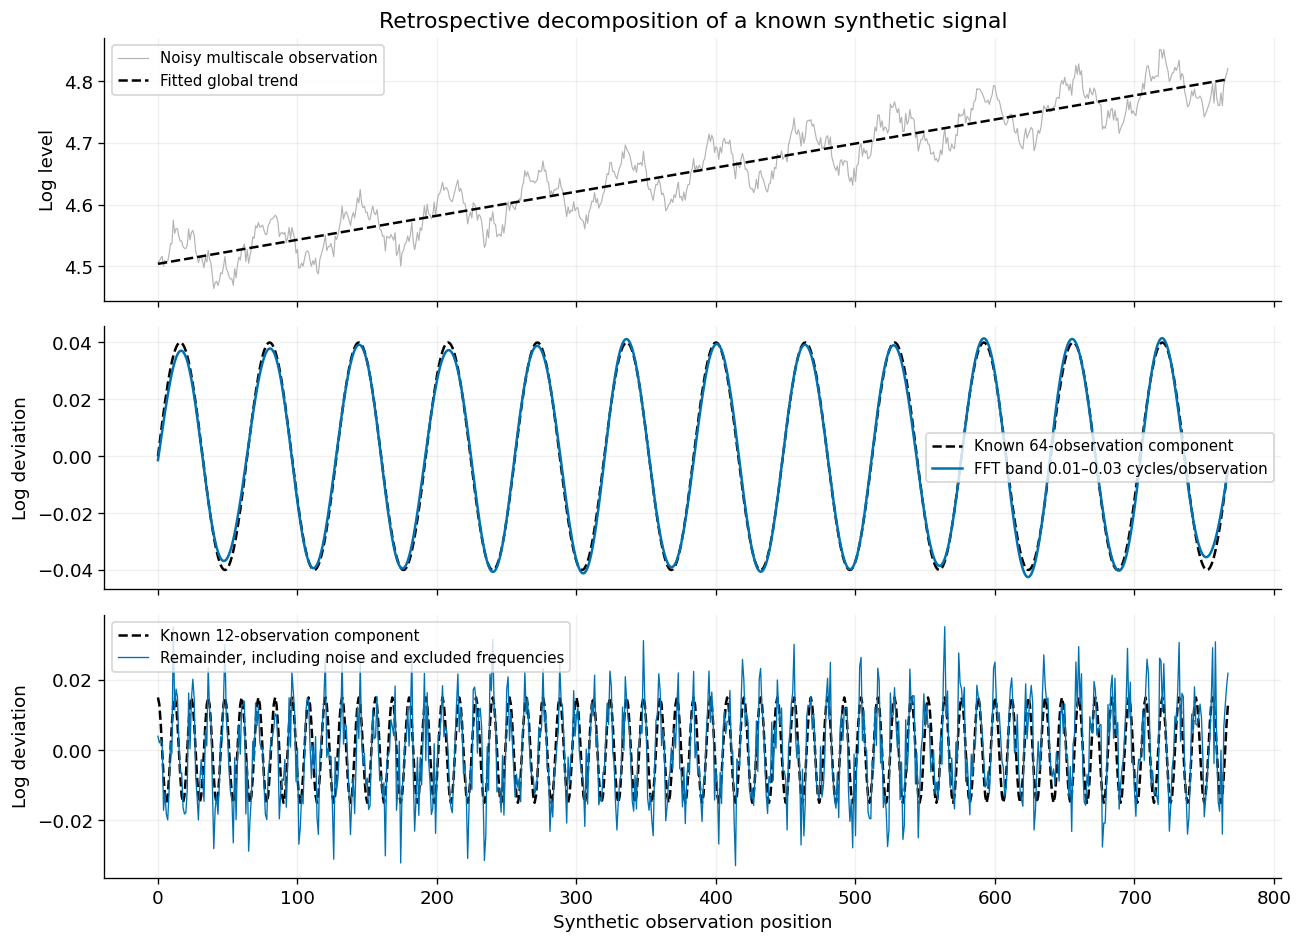

In [2]:
from tslab.spectral import SpectralSpec,SpectralEndpoint,fft_decompose,spectral_replay,harmonic_forecast
from tslab.spectral_evaluation import spectral_benchmark
from scipy.signal import periodogram
n=768
t=np.arange(n)
rng=np.random.default_rng(SEED)
trend=4.5+.0004*t
slow=.04*np.sin(2*np.pi*t/64)
fast=.015*np.cos(2*np.pi*t/12)
observed=trend+slow+fast+rng.normal(0,.008,n)
parts=fft_decompose(observed,low=.01,high=.03,detrend=True)
assert np.max(np.abs(parts['trend']+parts['band']+parts['remainder']-observed))<1e-12
components=pd.DataFrame({'observation':observed,'known_trend':trend,'known_slow':slow,
    'known_fast':fast,'fitted_trend':parts['trend'],'band':parts['band'],'remainder':parts['remainder']})
components.to_csv(OUT/'synthetic_components.csv',index_label='position')
fig,axes=plt.subplots(3,1,figsize=(11,8),sharex=True)
axes[0].plot(t,observed,color='.7',lw=.7,label='Noisy multiscale observation')
axes[0].plot(t,parts['trend'],'k--',label='Fitted global trend')
axes[0].set(ylabel='Log level',title='Retrospective decomposition of a known synthetic signal')
axes[1].plot(t,slow,'k--',label='Known 64-observation component')
axes[1].plot(t,parts['band'],label='FFT band 0.01–0.03 cycles/observation')
axes[1].set_ylabel('Log deviation')
axes[2].plot(t,fast,'k--',label='Known 12-observation component')
axes[2].plot(t,parts['remainder'],lw=.8,label='Remainder, including noise and excluded frequencies')
axes[2].set(xlabel='Synthetic observation position',ylabel='Log deviation')
for ax in axes: ax.legend(fontsize=9)
save_figure(fig,OUT,'01_known_components');

### 2. Separate power-spectrum estimation from reconstruction
A Hann taper helps spectral leakage in a periodogram but changes the observations.
It is not silently applied to an inverse FFT reconstruction. Finite-window FFT bins
are spaced 1/N cycles per observation; a narrow peak does not establish a persistent
economic cycle. This signal was constructed to contain two known oscillations.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS03_FFT_and_Bandpass_Decomposition/02_spectrum.png')


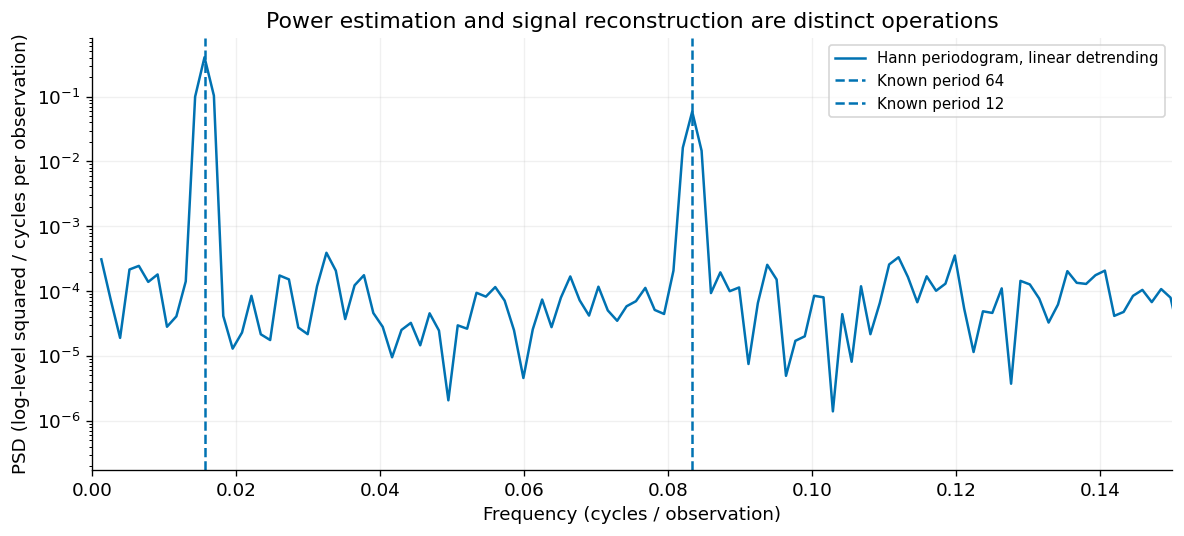

In [3]:
f,power=periodogram(observed,fs=1,window='hann',detrend='linear',scaling='density')
pd.DataFrame({'frequency_cycles_per_observation':f,'spectral_density':power}).to_csv(OUT/'synthetic_periodogram.csv',index=False)
fig,ax=plt.subplots()
ax.semilogy(f[1:],power[1:],label='Hann periodogram, linear detrending')
for freq,label in [(1/64,'Known period 64'),(1/12,'Known period 12')]:
    ax.axvline(freq,ls='--',label=label)
ax.set(xlim=(0,.15),xlabel='Frequency (cycles / observation)',ylabel='PSD (log-level squared / cycles per observation)',
       title='Power estimation and signal reconstruction are distinct operations')
ax.legend(fontsize=9)
save_figure(fig,OUT,'02_spectrum');

### 3. Archive causal endpoints and measure historical revision
The causal series is $s_t=[D(x_{t-w+1:t})]_{last}$: refit the trailing decomposition
at each date, then keep only the endpoint issued that day. It has no future data,
but still inherits endpoint and periodic-continuation artifacts. A zero-phase
interior curve fitted later is a different estimator.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS03_FFT_and_Bandpass_Decomposition/03_causality_and_revision.png')


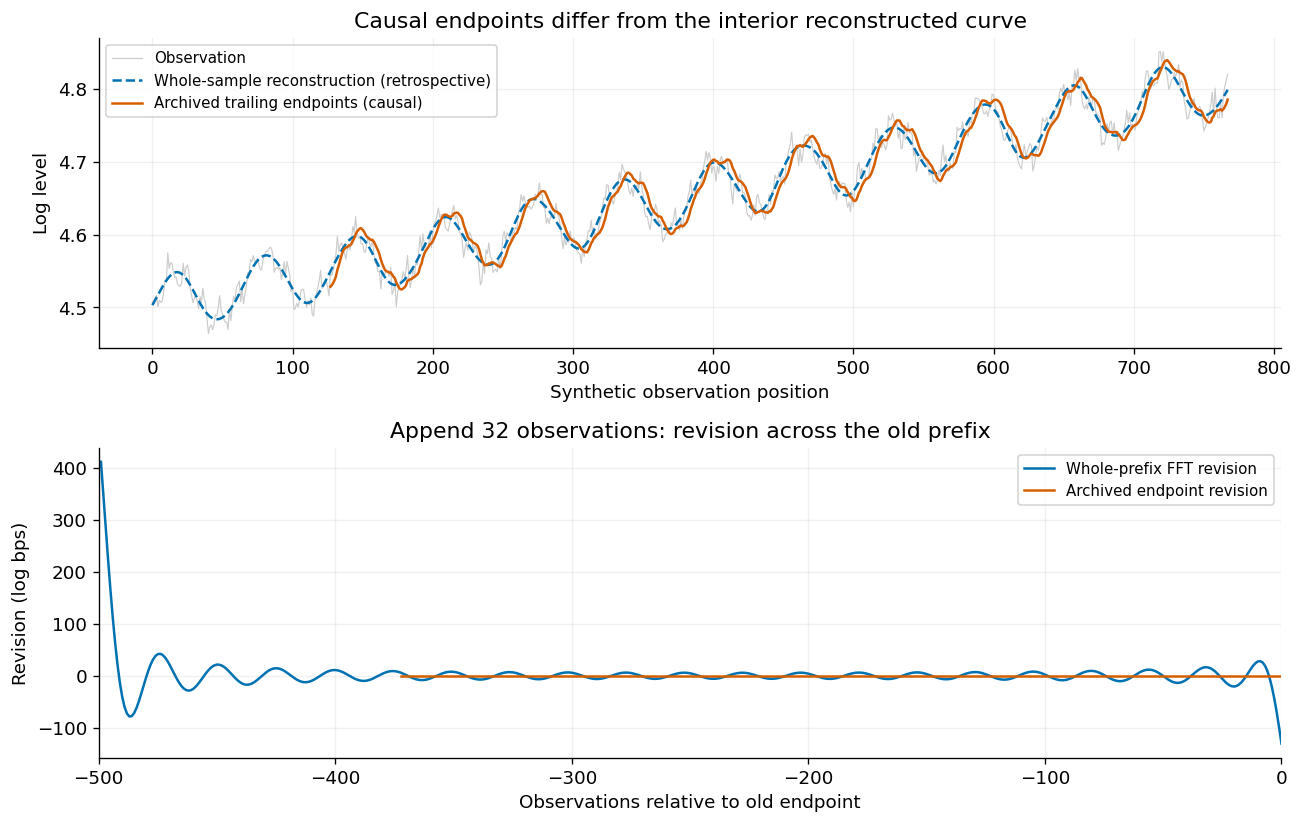

In [4]:
spec=SpectralSpec(window=128,low=0.,high=.04,detrend=True)
issued=spectral_replay(observed,spec)
cut=500
prefix=spectral_replay(observed[:cut],spec)
later=spectral_replay(observed[:cut+32],spec)
for key in prefix:
    np.testing.assert_allclose(prefix[key],later[key][:cut],equal_nan=True)
old=fft_decompose(observed[:cut],high=.04)['reconstructed']
new=fft_decompose(observed[:cut+32],high=.04)['reconstructed'][:cut]
revision=pd.DataFrame({'position':np.arange(cut),'retrospective_revision':new-old,
    'archived_endpoint_revision':later['reconstructed'][:cut]-prefix['reconstructed']})
revision.to_csv(OUT/'historical_revision.csv',index=False)
pd.DataFrame(issued).to_csv(OUT/'synthetic_causal_endpoints.csv',index_label='position')
fig,axes=plt.subplots(2,1,figsize=(11,7))
axes[0].plot(t,observed,color='.8',lw=.7,label='Observation')
axes[0].plot(t,fft_decompose(observed,high=.04)['reconstructed'],'--',label='Whole-sample reconstruction (retrospective)')
axes[0].plot(t,issued['reconstructed'],label='Archived trailing endpoints (causal)')
axes[0].set(xlabel='Synthetic observation position',ylabel='Log level',title='Causal endpoints differ from the interior reconstructed curve')
axes[1].plot(revision.position-cut+1,revision.retrospective_revision*1e4,label='Whole-prefix FFT revision')
axes[1].plot(revision.position-cut+1,revision.archived_endpoint_revision*1e4,label='Archived endpoint revision')
axes[1].set(xlim=(-cut,0),xlabel='Observations relative to old endpoint',ylabel='Revision (log bps)',title='Append 32 observations: revision across the old prefix')
for ax in axes: ax.legend(fontsize=9)
save_figure(fig,OUT,'03_causality_and_revision');

### 4. Stress Fourier extrapolation beyond a stationary cycle
Fourier extrapolation is a forecasting assumption in addition to smoothing. At each
origin, select two eligible FFT bins from the past 128 observations, then jointly
refit trend/sine/cosine coefficients by OLS and extrapolate 1–5 observations.
Compare a stable periodic toy process, a changing-frequency process and a random walk.
These are independent synthetic observed-signal targets, not stock-price forecasts.
No frequency is selected using a future error.

The harmonic fit is **unanchored**: its fitted curve need not meet the last observed
endpoint. A discontinuity there can produce a large one-step error even if the
estimated oscillation looks plausible. This is a property of this declared model,
not proof that all Fourier-based forecasting methods fail.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS03_FFT_and_Bandpass_Decomposition/04_fourier_stress_controls.png')


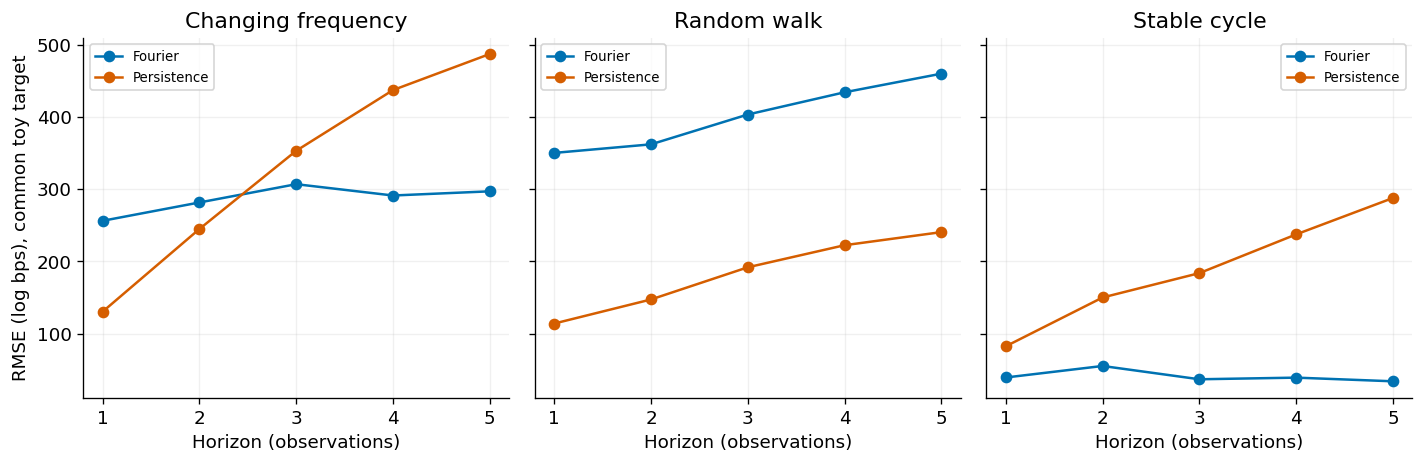

In [5]:
toy_rng=np.random.default_rng(SEED+1)
toy_n=640; u=np.arange(toy_n)
toys={'Stable cycle':4+.04*np.cos(2*np.pi*u/32)+toy_rng.normal(0,.004,toy_n),
      'Changing frequency':4+.04*np.sin(2*np.pi*(.015*u+.00006*u**2))+toy_rng.normal(0,.004,toy_n),
      'Random walk':4+toy_rng.normal(0,.01,toy_n).cumsum()}
toy_rows=[]
for name,series in toys.items():
    for origin in range(200,toy_n-5,10):
        forecast,_=harmonic_forecast(series[:origin+1],window=128,harmonics=2)
        for h in range(1,6):
            for method,pred in [('Fourier',forecast[h-1]),('Persistence',series[origin])]:
                toy_rows.append({'process':name,'origin':origin,'horizon':h,'model':method,
                                 'squared_error':(pred-series[origin+h])**2})
toy_records=pd.DataFrame(toy_rows)
toy_scores=toy_records.groupby(['process','horizon','model']).squared_error.mean().pow(.5).rename('RMSE').reset_index()
toy_scores.to_csv(OUT/'toy_forecast_scores.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(12,4),sharey=True)
for ax,(name,part) in zip(axes,toy_scores.groupby('process')):
    for method,group in part.groupby('model'):
        ax.plot(group.horizon,group.RMSE*1e4,'o-',label=method)
    ax.set(title=name,xlabel='Horizon (observations)');ax.legend(fontsize=8)
axes[0].set_ylabel('RMSE (log bps), common toy target')
save_figure(fig,OUT,'04_fourier_stress_controls');

### 5. Maintain two stock-data research tracks
Use fixed low-pass and trend-plus-band variants of the archived FFT endpoint target.
Each filter defines its own smoothed target; their raw target RMSEs cannot rank the filters.
The stock candidate extrapolates the **smoothed endpoint history**, not raw prices.
The fit audit exports both the fitted endpoint gap and first predicted change, so
the unanchored extrapolator's boundary mismatch is inspectable.

For actual returns, fit only mature historical pairs
$$r_{j+1}=a+b(s_j-s_{j-1})+\varepsilon_{j+1}.$$
Then project those lagged slopes from the Fourier path and sum daily return estimates.
Actual returns remain supervised labels. This is an explicit two-stage return model,
not an assertion that a smoothed change equals an actual return.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS03_FFT_and_Bandpass_Decomposition/05_separate_stock_scorecards.png')


,filter_id,model,n,RMSE,MSE_skill
40,FFT_w128_band_0.01_0.04,Fourier_plus_bridge,170,0.057542,-69.260287
41,FFT_w128_band_0.01_0.04,filter_drift,170,0.007092,-0.067364
42,FFT_w128_band_0.01_0.04,filter_nochange,170,0.006865,0.000000
43,FFT_w128_band_0.01_0.04,persistence,170,0.016779,-4.974129
44,FFT_w128_band_0.01_0.04,smooth_slope,170,0.009811,-1.042521
85,FFT_w128_band_0.0_0.04,Fourier_plus_bridge,170,0.071275,-77.213446
86,FFT_w128_band_0.0_0.04,filter_drift,170,0.008326,-0.067252
87,FFT_w128_band_0.0_0.04,filter_nochange,170,0.008059,0.000000
88,FFT_w128_band_0.0_0.04,persistence,170,0.018096,-4.041800
89,FFT_w128_band_0.0_0.04,smooth_slope,170,0.011262,-0.952738


,filter_id,model,n,RMSE,MSE_skill
16,FFT_w128_band_0.01_0.04,Fourier_plus_bridge,170,0.027508,-0.315524
17,FFT_w128_band_0.01_0.04,raw_drift,170,0.024842,-0.072831
18,FFT_w128_band_0.01_0.04,smooth_slope,170,0.027187,-0.284955
19,FFT_w128_band_0.01_0.04,zero,170,0.023984,0.000000
61,FFT_w128_band_0.0_0.04,Fourier_plus_bridge,170,0.027788,-0.342372
62,FFT_w128_band_0.0_0.04,raw_drift,170,0.024842,-0.072831
63,FFT_w128_band_0.0_0.04,smooth_slope,170,0.027755,-0.339255
64,FFT_w128_band_0.0_0.04,zero,170,0.023984,0.000000


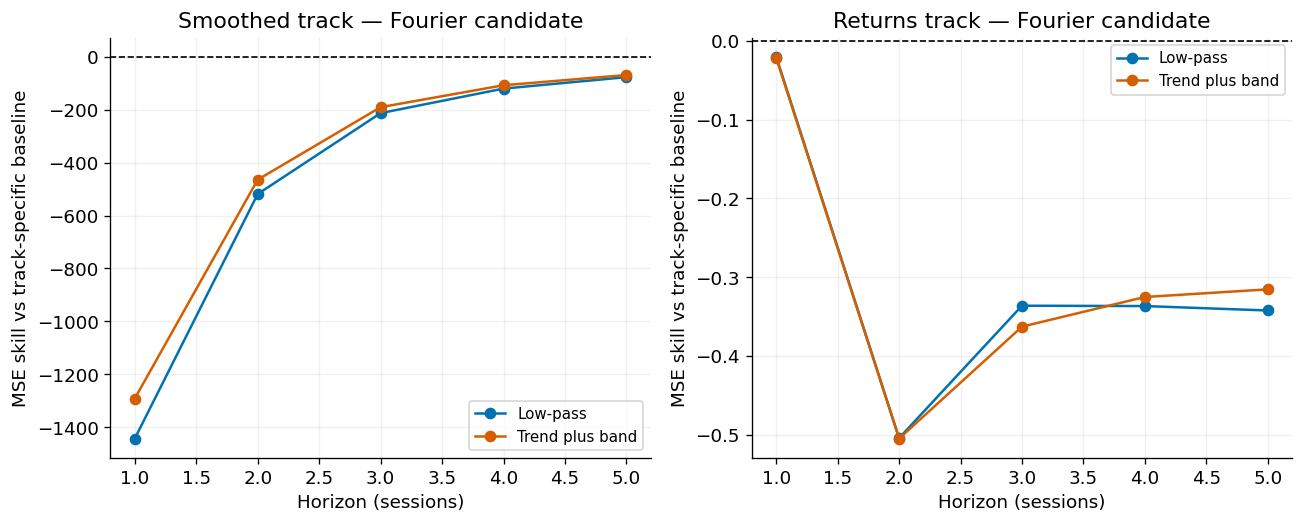

In [6]:
market_x,metadata=load_snapshot(ROOT/'inputs'/'SPY_adjusted_demo.csv',ROOT/'inputs'/'SPY_adjusted_demo.metadata.json')
specs={'Low-pass':SpectralSpec(window=128,low=0.,high=.04),
       'Trend plus band':SpectralSpec(window=128,low=.01,high=.04)}
records=[];audits=[]
for name,setting in specs.items():
    frame,endpoint,audit=spectral_benchmark(market_x,setting,start=500,step=10)
    frame['filter_label']=name; audit['filter_label']=name
    records.append(frame);audits.append(audit)
records=pd.concat(records,ignore_index=True)
fit_audit=pd.concat(audits,ignore_index=True)
scores=scorecard(records)
records.to_csv(OUT/'historical_forecasts.csv',index=False)
fit_audit.to_csv(OUT/'fit_audit.csv',index=False)
for track in ['smoothed','returns']:
    scores[scores.track==track].to_csv(OUT/f'{track}_scorecard.csv',index=False)
    display(scores.query('track==@track and horizon==5')[['filter_id','model','n','RMSE','MSE_skill']].round(6))
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for ax,track in zip(axes,['smoothed','returns']):
    for label,frame in records.groupby('filter_label'):
        group=scorecard(frame).query("track==@track and model=='Fourier_plus_bridge'")
        ax.plot(group.horizon,group.MSE_skill,'o-',label=label)
    ax.axhline(0,color='black',ls='--',lw=1)
    ax.set(title=f'{track.title()} track — Fourier candidate',xlabel='Horizon (sessions)',ylabel='MSE skill vs track-specific baseline')
    ax.legend(fontsize=9)
save_figure(fig,OUT,'05_separate_stock_scorecards');

## Checks
Check exact component reconstruction, immutable prefixes, poisoned-future immunity,
checkpoint/resume and nonmutating path propagation. A causal implementation can
still forecast poorly; passing these checks establishes timing correctness, not skill.

In [7]:
poison=observed.copy();poison[cut:]+=100
poisoned=spectral_replay(poison,spec)
np.testing.assert_allclose(issued['reconstructed'][:cut],poisoned['reconstructed'][:cut],equal_nan=True)
engine=SpectralEndpoint(spec)
for value in observed[:cut]:engine.update(value)
state=engine.checkpoint()
engine.project([observed[cut-1]]*5)
assert state==engine.checkpoint()
restored=SpectralEndpoint.restore(state)
resumed=np.array([restored.update(v)['reconstructed'] for v in observed[cut:]])
np.testing.assert_allclose(resumed,issued['reconstructed'][cut:])
checks={'component_reconstruction':True,'prefix_invariance':True,'future_poison_invariance':True,
        'checkpoint_equivalence':True,'projection_nonmutating':True}
(OUT/'checks.json').write_text(json.dumps(checks,indent=2))
display(pd.DataFrame([checks]))
write_research_manifest(OUT,{'spectral_filters':{k:asdict(v) for k,v in specs.items()},
    'start':500,'step':10,'harmonic_window':128,'harmonics':2,'return_bridge':'OLS next raw return on current smoothed slope',
    'selection':'none; fixed band settings, past-only per-origin amplitude ranking'},metadata,seed=SEED)
maximum=float(np.max(np.abs(revision.retrospective_revision))*1e4)
summary=f"## Observed results\n\nAppending 32 observations changes the old whole-prefix FFT curve by up to **{maximum:.2f} log bps** over that historical prefix in this synthetic example; archived causal endpoints have **zero revision**. Both stock tracks retain matched-origin baseline comparisons. The unanchored Fourier extrapolator fits poorly on the stock example; its endpoint gaps are retained in the audit rather than repaired using future outcomes."
(OUT/'observed_summary.md').write_text(summary)
print('PASS: FFT reconstruction, causal state and prefix checks.')

PASS: FFT reconstruction, causal state and prefix checks.


,component_reconstruction,prefix_invariance,future_poison_invariance,checkpoint_equivalence,projection_nonmutating
0,True,True,True,True,True


## Next Steps
TS04 adds fitted classical models and nested chronological model selection. The SPY
snapshot ends 2026-10-01 and has already been examined in this project. These
spectral demonstrations are exploratory, with no untouched holdout or trading claim.

References: [NumPy real FFT](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfft.html),
[SciPy periodogram](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.periodogram.html).